In [2]:
%pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow streamlit

  Obtaining dependency information for tensorflow from https://files.pythonhosted.org/packages/8f/a2/6d7e6a738e302530586d484895de2cf3fc158ad9c73b4504a670b2956dd9/tensorflow-2.21.0-cp311-cp311-win_amd64.whl.metadata
  Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl.metadata (4.5 kB)
Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl (350.8 MB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'c:\\Users\\ASUS\\AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\tensorflow\\core\\framework\\graph_debug_info_pb2.py'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Obtaining dependency information for tensorflow from https://files.pythonhosted.org/packages/8f/a2/6d7e6a738e302530586d484895de2cf3fc158ad9c73b4504a670b2956dd9/tensorflow-2.21.0-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for kagglehub from https://files.pythonhosted.org/packages/0e/49/008002e0bf9bb4cfca85ce5e44314aef39f9a33dd15e31904d659ebca2d8/kagglehub-1.0.3-py3-none-any.whl.metadata
     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     ---------------------------- --------- 30.7/40.4 kB 435.7 kB/s eta 0:00:01
     -------------------------------------- 40.4/40.4 kB 478.5 kB/s eta 0:00:00
  Obtaining dependency information for absl-py>=1.0.0 from https://files.pythonhosted.org/packages/b3/7d/01e62f59e4166af1be6238d9f2b7f3453630c51b8044b412d05b5606532a/absl_py-2.5.1-py3-none-any.whl.metadata
  Obtaining dependency information for astunparse>=1.6.0 from https://f

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# ==========================================
# IMPORT LIBRARY
# KLASIFIKASI IMAGE OCEANICLIFE MENGGUNAKAN CNN
# ==========================================

# Library dasar
import os
import json
import time
import math
import random

# Pengolahan data
import numpy as np
import pandas as pd

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Pengolahan gambar
from PIL import Image

# Deep Learning
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# Callback training
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Evaluasi model
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ==========================================
# CEK VERSI DAN PERANGKAT
# ==========================================

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

print("\nSemua library berhasil di-import!")

TensorFlow Version: 2.21.0
NumPy Version: 2.4.0
Pandas Version: 3.1.0
GPU Available: []

Semua library berhasil di-import!


In [9]:
# ==========================================
# KONFIGURASI PERANGKAT
# ==========================================

# Menggunakan CPU
tf.config.set_visible_devices([], 'GPU')

print("Perangkat yang digunakan: CPU")
print("CPU Available:", tf.config.list_physical_devices('CPU'))

Perangkat yang digunakan: CPU
CPU Available: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [4]:

# ==========================================
# KONFIGURASI DATASET OCEANICLIFE
# ==========================================

import os
import math
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

BASE_DIR = r"C:\Users\ASUS\OneDrive\Documents\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset"

IMG_SIZE = (160, 160)  # Ukuran gambar
BATCH_SIZE = 32

EPOCHS = 15  # Fase 1: latih kepala klasifikasi
FINE_TUNE_EPOCHS = 5  # Fase 2: fine-tuning

SEED = 42
WEIGHTS = "imagenet"

OUT_DIR = "output_oceaniclife"
os.makedirs(OUT_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)

analysis = {}  # Analisis otomatis untuk dashboard Streamlit

# ==========================================
# CEK FOLDER DATASET
# ==========================================

if not os.path.exists(BASE_DIR):
    raise FileNotFoundError(
        f"Folder dataset tidak ditemukan: {BASE_DIR}"
    )

print("Dataset ditemukan:", BASE_DIR)

# ==========================================
# MENGAMBIL SEMUA FILE GAMBAR
# ==========================================

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")
out_abs = os.path.abspath(OUT_DIR)

image_paths = []

for root, _, files in os.walk(BASE_DIR):

    if os.path.abspath(root).startswith(out_abs):
        continue

    for f in files:
        if f.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root, f))

image_paths = sorted(image_paths)

print("Total gambar:", len(image_paths))

if not image_paths:
    raise RuntimeError(
        "Tidak ada gambar (jpg/jpeg/png/bmp/gif) di BASE_DIR. "
        "Periksa path dataset."
    )


Dataset ditemukan: C:\Users\ASUS\OneDrive\Documents\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset
Total gambar: 7990


In [6]:

# ==========================================
# MENENTUKAN KELAS DATASET
# ==========================================

import os
import json

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

index_to_class = {
    index: name for name, index in class_to_index.items()
}

NUM_CLASSES = len(class_names)

print("Jumlah kelas:", NUM_CLASSES)

print("\nDaftar kelas:")
for name, index in class_to_index.items():
    print(f"{index} = {name}")

# Menyimpan nama kelas ke file JSON
with open(os.path.join(OUT_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f, indent=4)

print("\nNama kelas berhasil disimpan!")


Jumlah kelas: 8

Daftar kelas:
0 = Fish
1 = Coral
2 = Shark
3 = Octopuses
4 = Crustaceans
5 = Seaweed
6 = Sponges
7 = Other marine organisms

Nama kelas berhasil disimpan!


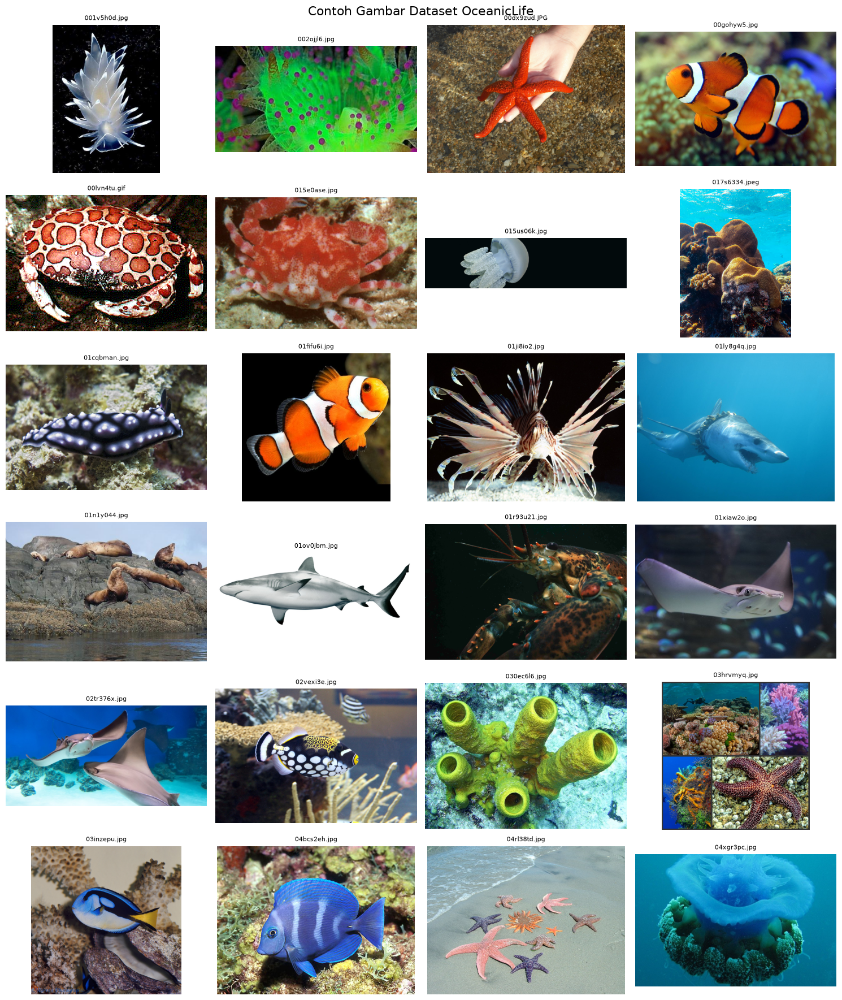

In [7]:
# ==========================================
# MENAMPILKAN CONTOH DATASET
# ==========================================

sample_paths = image_paths[:24]

rows = math.ceil(len(sample_paths) / 4)

plt.figure(figsize=(15, rows * 3))

for i, path in enumerate(sample_paths):

    try:
        img = Image.open(path).convert("RGB")

        plt.subplot(rows, 4, i + 1)
        plt.imshow(img)
        plt.title(os.path.basename(path), fontsize=8)
        plt.axis("off")

    except Exception as e:
        print("Gagal membaca:", path)

plt.suptitle("Contoh Gambar Dataset OceanicLife", fontsize=16)

plt.tight_layout()
plt.show()

In [4]:

# ==========================================
# PELABELAN GAMBAR SECARA MANUAL
# OCEANICLIFE DATASET
# ==========================================

import os
import math
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import clear_output

# ==========================================
# 1. KONFIGURASI
# ==========================================

BASE_DIR = r"C:\Users\ASUS\OneDrive\Documents\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset"

OUT_DIR = "output_oceaniclife"

LABEL_MODE = "batch"
GRID = 12

os.makedirs(OUT_DIR, exist_ok=True)

label_file = os.path.join(
    OUT_DIR, "oceaniclife_labels.csv"
)

if not os.path.exists(BASE_DIR):
    raise FileNotFoundError(
        "Folder dataset tidak ditemukan: " + BASE_DIR
    )

# ==========================================
# 2. DAFTAR KELAS
# ==========================================

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

index_to_class = {
    index: name for name, index in class_to_index.items()
}

NUM_CLASSES = len(class_names)

# ==========================================
# 3. MENGUMPULKAN GAMBAR
# ==========================================

image_paths = []

for root, dirs, files in os.walk(BASE_DIR):
    for file in files:
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".gif")
        ):
            image_paths.append(
                os.path.join(root, file)
            )

image_paths.sort()

print("TOTAL GAMBAR DITEMUKAN:", len(image_paths))

# ==========================================
# 4. MEMBACA CSV
# ==========================================

columns = ["filepath", "filename", "label", "label_id"]

if os.path.exists(label_file):
    labels_df = pd.read_csv(label_file)
else:
    labels_df = pd.DataFrame(columns=columns)

for col in columns:
    if col not in labels_df.columns:
        labels_df[col] = None

labels_df = labels_df.dropna(
    subset=["filename", "label_id"]
).copy()

labels_df["label_id"] = pd.to_numeric(
    labels_df["label_id"], errors="coerce"
)

labels_df = labels_df.dropna(
    subset=["label_id"]
).copy()

labels_df["label_id"] = labels_df["label_id"].astype(int)

labels_df = labels_df[
    labels_df["label_id"].between(0, NUM_CLASSES - 1)
].copy()

# ==========================================
# 5. MENENTUKAN GAMBAR BELUM DILABELI
# ==========================================

def rel_name(path):
    return os.path.relpath(path, BASE_DIR)

labeled_files = set(
    labels_df["filename"].astype(str)
)

todo = [
    path for path in image_paths
    if rel_name(path) not in labeled_files
]

print("SUDAH DILABELI:", len(labels_df))
print("BELUM DILABELI:", len(todo))

print("\nDAFTAR KELAS:")
for i, name in enumerate(class_names):
    print(f"{i} = {name}")

# ==========================================
# 6. FUNGSI PENYIMPANAN
# ==========================================

new_rows = []

def add_row(path, label_id):
    new_rows.append({
        "filepath": path,
        "filename": rel_name(path),
        "label": index_to_class[label_id],
        "label_id": label_id
    })

def save_labels():
    global labels_df, new_rows

    if new_rows:
        labels_df = pd.concat(
            [labels_df, pd.DataFrame(new_rows)],
            ignore_index=True
        )

        new_rows = []

    labels_df.to_csv(label_file, index=False)

# ==========================================
# 7. PROSES PELABELAN BATCH
# ==========================================

stop = False

for start in range(0, len(todo), GRID):

    batch_paths = todo[start:start + GRID]

    n = len(batch_paths)
    cols = 4
    nrows = math.ceil(n / cols)

    clear_output(wait=True)

    fig, axes = plt.subplots(
        nrows, cols,
        figsize=(14, nrows * 3.6)
    )

    axes = axes.flatten()

    for i, path in enumerate(batch_paths):

        try:
            img = Image.open(path).convert("RGB")
            axes[i].imshow(img)
        except Exception:
            axes[i].text(
                0.5, 0.5, "Gambar gagal dibuka",
                ha="center"
            )

        axes[i].set_title(f"Gambar {i + 1}")
        axes[i].axis("off")

    for j in range(n, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

    print("\nDAFTAR KELAS:")
    for i, name in enumerate(class_names):
        print(f"{i} = {name}")

    print(
        f"\nGambar {start + 1} sampai {start + n} "
        f"dari {len(todo)}"
    )

    while True:

        ans = input(
            f"Masukkan {n} angka label berurutan "
            "(contoh: 003177205641), atau q untuk berhenti: "
        ).strip().lower()

        if ans == "q":
            stop = True
            break

        code_str = ans.replace(" ", "").replace(",", "")

        if (
            len(code_str) == n
            and all(ch in "01234567" for ch in code_str)
        ):
            break

        print("Input salah! Masukkan tepat", n, "angka dari 0 sampai 7.")

    if stop:
        break

    for path, ch in zip(batch_paths, code_str):
        add_row(path, int(ch))

    save_labels()

    print("Batch berhasil disimpan!")

# ==========================================
# 8. HASIL PELABELAN
# ==========================================

save_labels()

clear_output(wait=True)

print("PROSES PELABELAN SELESAI / DIHENTIKAN")
print("TOTAL GAMBAR BERLABEL:", len(labels_df))

print("\nJUMLAH GAMBAR PER KELAS:")

print(
    labels_df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print("\nFILE CSV TERSIMPAN:")
print(label_file)


PROSES PELABELAN SELESAI / DIHENTIKAN
TOTAL GAMBAR BERLABEL: 48

JUMLAH GAMBAR PER KELAS:
label
Fish                      26
Coral                      0
Shark                      0
Octopuses                  1
Crustaceans                4
Seaweed                    0
Sponges                    0
Other marine organisms    17
Name: count, dtype: int64

FILE CSV TERSIMPAN:
output_oceaniclife\oceaniclife_labels.csv


In [6]:
# ==========================================
# PELABELAN GAMBAR SECARA MANUAL
# ==========================================

LABEL_MODE = "batch"       # "batch" = 12 gambar per input | "single" = satu per satu
GRID = 12

try:
    from IPython.display import clear_output
except ImportError:
    clear_output = lambda *a, **k: None

label_file = os.path.join(OUT_DIR, "oceaniclife_labels.csv")


def rel_name(path):
    try:
        return os.path.relpath(path, BASE_DIR)
    except ValueError:
        return os.path.basename(path)


# Jika CSV sudah pernah dibuat, lanjutkan gambar yang belum diberi label.
if os.path.exists(label_file):
    labels_df = pd.read_csv(label_file)

    # Memastikan kolom yang dibutuhkan tersedia
    if "filename" not in labels_df.columns and "filepath" in labels_df.columns:
        labels_df["filename"] = labels_df["filepath"].apply(rel_name)

    if "filepath" not in labels_df.columns:
        labels_df["filepath"] = labels_df["filename"].apply(
            lambda f: os.path.join(BASE_DIR, f)
        )

    if "label" not in labels_df.columns:
        labels_df["label"] = labels_df["label_id"].map(
            lambda x: "skip" if x < 0 else index_to_class[int(x)]
        )

else:
    labels_df = pd.DataFrame(
        columns=["filepath", "filename", "label", "label_id"]
    )

labeled_files = set(labels_df["filename"].tolist())
todo = [p for p in image_paths if rel_name(p) not in labeled_files]

print("DAFTAR KELAS:")
for index, name in enumerate(class_names):
    print(f"{index} = {name}")

print(f"\nSudah dilabeli : {len(labeled_files)}")
print(f"Belum dilabeli : {len(todo)}\n")

new_rows = []


def add_row(path, label_id):
    if label_id < 0:
        name = "skip"
    else:
        name = index_to_class[label_id]
    new_rows.append({
        "filepath": path, "filename": rel_name(path),
        "label": name, "label_id": label_id
    })


def save_labels():
    global labels_df, new_rows
    if new_rows:
        labels_df = pd.concat([labels_df, pd.DataFrame(new_rows)], ignore_index=True)
        new_rows = []
    labels_df.to_csv(label_file, index=False)


valid_chars = "-" + "".join(str(i) for i in range(NUM_CLASSES))
stop = False

if LABEL_MODE == "batch":

    for start in range(0, len(todo), GRID):
        batch_paths = todo[start:start + GRID]
        n = len(batch_paths)
        cols = 4
        nrows = math.ceil(n / cols)

        clear_output(wait=True)
        plt.figure(figsize=(14, nrows * 3.6))
        for i, path in enumerate(batch_paths):
            try:
                img = Image.open(path).convert("RGB")
            except Exception:
                img = Image.new("RGB", (64, 64), "black")
            plt.subplot(nrows, cols, i + 1)
            plt.imshow(img)
            plt.title(f"[{i + 1}]", fontsize=16, fontweight="bold")
            plt.axis("off")
        plt.tight_layout()
        plt.show()

        print("Kelas: " + " | ".join(f"{i}={nm}" for i, nm in enumerate(class_names)))
        print(f"Gambar {start + 1}-{start + n} dari {len(todo)} yang belum dilabeli")

        while True:
            ans = input(
                f"Label {n} gambar (mis. 003-1770...; '-' = lewati; q = berhenti): "
            ).strip().lower()
            if ans == "q":
                stop = True
                break
            code_str = ans.replace(" ", "").replace(",", "")
            if len(code_str) == n and all(ch in valid_chars for ch in code_str):
                break
            print(f"Input tidak valid: butuh tepat {n} karakter (angka 0-{NUM_CLASSES - 1} atau '-').")

        if stop:
            break

        for path, ch in zip(batch_paths, code_str):
            add_row(path, -1 if ch == "-" else int(ch))
        save_labels()

else:

    for path in todo:

        try:
            img = Image.open(path).convert("RGB")

            clear_output(wait=True)
            plt.figure(figsize=(5, 5))
            plt.imshow(img)
            plt.title(os.path.basename(path))
            plt.axis("off")
            plt.show()

            print("Nama gambar:", os.path.basename(path))

            label_input = input(
                f"Masukkan nomor kelas (0-{NUM_CLASSES - 1}), skip, atau q untuk berhenti: "
            ).strip().lower()

            if label_input == "q":
                break

            if label_input == "skip":
                add_row(path, -1)
                save_labels()
                continue

            if not label_input.isdigit() or int(label_input) not in range(NUM_CLASSES):
                print("Input tidak valid.")
                continue

            add_row(path, int(label_input))
            save_labels()
            print("Label berhasil disimpan:", index_to_class[int(label_input)])

        except Exception as e:
            print("Gagal memproses gambar:", e)

save_labels()

clear_output(wait=True)
print("Proses pelabelan selesai / dihentikan.")
print("Gambar yang sudah dilabeli (tidak termasuk skip):", int((labels_df["label_id"] >= 0).sum()))
print("\nJumlah per kelas:")
print(labels_df[labels_df["label_id"] >= 0]["label"].value_counts().reindex(class_names).fillna(0).astype(int).to_string())

Proses pelabelan selesai / dihentikan.
Gambar yang sudah dilabeli (tidak termasuk skip): 60

Jumlah per kelas:
label
Fish                      33
Coral                      0
Shark                      0
Octopuses                  1
Crustaceans                5
Seaweed                    0
Sponges                    0
Other marine organisms    21


In [7]:
# Membaca label sebelumnya
if os.path.exists(label_file):
    labels_df = pd.read_csv(label_file)
else:
    labels_df = pd.DataFrame(columns=["filename", "label_id"])

# Mengambil gambar yang sudah dilabeli
sudah_dilabeli = set(
    labels_df.loc[
        labels_df["label_id"] >= 0,
        "filename"
    ]
)

# Mengambil gambar yang belum dilabeli
belum_dilabeli = [
    p for p in image_paths
    if os.path.basename(p) not in sudah_dilabeli
]

print("Sudah dilabeli:", len(sudah_dilabeli))
print("Belum dilabeli:", len(belum_dilabeli))

Sudah dilabeli: 60
Belum dilabeli: 7930


TOTAL GAMBAR DITEMUKAN: 7990


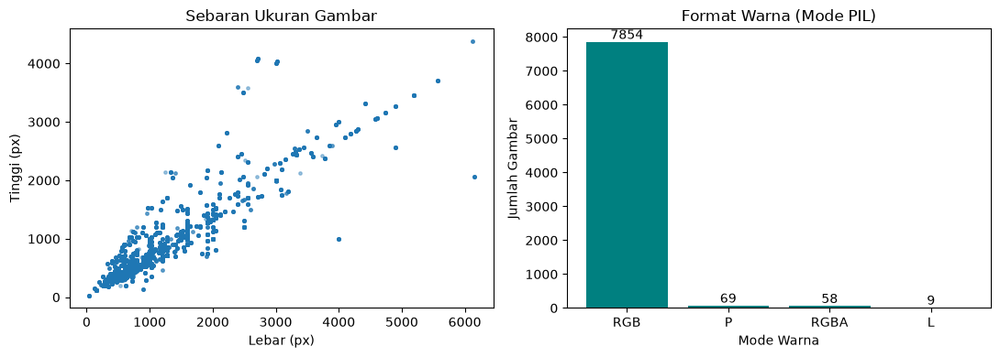


ANALISIS:
Dari 7990 file, terdapat 7990 gambar valid. Lebar rata-rata 1206px (min 32, maks 6144); tinggi rata-rata 879px (min 32, maks 4378). Mode warna: {'RGB': 7854, 'P': 69, 'RGBA': 58, 'L': 9}. File rusak: 0. Semua gambar akan di-resize ke 160x160 dan dibaca sebagai RGB.

Tidak ditemukan file gambar rusak.

PEMERIKSAAN GAMBAR SELESAI
Total gambar       : 7990
Gambar valid       : 7990
Gambar rusak       : 0
Ukuran target      : (160, 160)
Format warna       : {'RGB': 7854, 'P': 69, 'RGBA': 58, 'L': 9}
Lokasi hasil grafik: output_oceaniclife


In [10]:

# ==========================================
# (a) UKURAN GAMBAR, FORMAT WARNA, KUALITAS
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# ==========================================
# 1. KONFIGURASI
# ==========================================

BASE_DIR = r"C:\Users\ASUS\OneDrive\Documents\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset"

OUT_DIR = "output_oceaniclife"
IMG_SIZE = (160, 160)

os.makedirs(OUT_DIR, exist_ok=True)

# Menyiapkan dictionary analisis
if "analysis" not in globals():
    analysis = {}

# ==========================================
# 2. MENGUMPULKAN GAMBAR
# ==========================================

image_paths = []

for root, dirs, files in os.walk(BASE_DIR):
    for file in files:
        if file.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".gif")
        ):
            image_paths.append(
                os.path.join(root, file)
            )

image_paths.sort()

print("TOTAL GAMBAR DITEMUKAN:", len(image_paths))

# ==========================================
# 3. MEMERIKSA UKURAN DAN FORMAT GAMBAR
# ==========================================

widths = []
heights = []
modes = []
bad = []

for p in image_paths:
    try:
        with Image.open(p) as im:
            w, h = im.size
            m = im.mode
            im.verify()

        widths.append(w)
        heights.append(h)
        modes.append(m)

    except Exception:
        bad.append(p)

# Mengubah data menjadi array
widths = np.array(widths)
heights = np.array(heights)

# Menghitung jumlah format warna
mode_counts = pd.Series(modes).value_counts()

# ==========================================
# 4. VISUALISASI DATA
# ==========================================

if len(widths) > 0:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(11, 4)
    )

    # Grafik sebaran ukuran gambar
    axes[0].scatter(
        widths,
        heights,
        s=6,
        alpha=0.4
    )

    axes[0].set_title("Sebaran Ukuran Gambar")
    axes[0].set_xlabel("Lebar (px)")
    axes[0].set_ylabel("Tinggi (px)")

    # Grafik format warna
    b = axes[1].bar(
        mode_counts.index.astype(str),
        mode_counts.values,
        color="teal"
    )

    axes[1].bar_label(b)

    axes[1].set_title("Format Warna (Mode PIL)")
    axes[1].set_xlabel("Mode Warna")
    axes[1].set_ylabel("Jumlah Gambar")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUT_DIR,
            "3_image_properties.png"
        ),
        dpi=120
    )

    plt.show()

    # ==========================================
    # 5. ANALISIS HASIL
    # ==========================================

    analysis["eda_ukuran"] = (
        f"Dari {len(image_paths)} file, "
        f"terdapat {len(widths)} gambar valid. "
        f"Lebar rata-rata {widths.mean():.0f}px "
        f"(min {widths.min()}, maks {widths.max()}); "
        f"tinggi rata-rata {heights.mean():.0f}px "
        f"(min {heights.min()}, maks {heights.max()}). "
        f"Mode warna: {mode_counts.to_dict()}. "
        f"File rusak: {len(bad)}. "
        f"Semua gambar akan di-resize ke "
        f"{IMG_SIZE[0]}x{IMG_SIZE[1]} "
        f"dan dibaca sebagai RGB."
    )

    print("\nANALISIS:")
    print(analysis["eda_ukuran"])

else:
    print("Tidak ada gambar valid yang ditemukan.")

# ==========================================
# 6. INFORMASI FILE RUSAK
# ==========================================

if bad:

    print(
        f"\nPERINGATAN: {len(bad)} file gambar rusak:"
    )

    print("\n".join(bad[:20]))

else:

    print("\nTidak ditemukan file gambar rusak.")

# ==========================================
# 7. RINGKASAN
# ==========================================

print("\n================================")
print("PEMERIKSAAN GAMBAR SELESAI")
print("================================")

print("Total gambar       :", len(image_paths))
print("Gambar valid       :", len(widths))
print("Gambar rusak       :", len(bad))
print("Ukuran target      :", IMG_SIZE)
print("Format warna       :", mode_counts.to_dict())
print("Lokasi hasil grafik:", OUT_DIR)


In [12]:

# ==========================================
# MEMBACA LABEL DAN MEMERIKSA JUMLAH DATA
# ==========================================

import os
import pandas as pd

# ==========================================
# 1. KONFIGURASI
# ==========================================

BASE_DIR = r"C:\Users\ASUS\OneDrive\Documents\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset"

OUT_DIR = "output_oceaniclife"
label_file = os.path.join(OUT_DIR, "oceaniclife_labels.csv")

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

index_to_class = {
    i: name for i, name in enumerate(class_names)
}

# ==========================================
# 2. MEMBACA CSV
# ==========================================

if not os.path.exists(label_file):
    raise FileNotFoundError(
        f"File label tidak ditemukan: {label_file}"
    )

labels_df = pd.read_csv(label_file)

labels_df.columns = labels_df.columns.str.strip()

print("KOLOM CSV:", labels_df.columns.tolist())

if len(labels_df) == 0:
    raise ValueError(
        "CSV masih kosong! Jalankan pelabelan gambar manual terlebih dahulu."
    )

# Memastikan kolom tersedia
required_columns = ["filename", "label_id"]

for col in required_columns:
    if col not in labels_df.columns:
        raise ValueError(f"Kolom {col} tidak ditemukan dalam CSV.")

# ==========================================
# 3. MEMERIKSA LABEL VALID
# ==========================================

labels_df["label_id"] = pd.to_numeric(
    labels_df["label_id"],
    errors="coerce"
)

df = labels_df.dropna(
    subset=["label_id", "filename"]
).copy()

df["label_id"] = df["label_id"].astype(int)

# Hanya mengambil label 0 sampai 7
df = df[
    df["label_id"].between(0, len(class_names) - 1)
].copy()

# ==========================================
# 4. MEMBUAT LOKASI GAMBAR
# ==========================================

def get_image_path(row):

    # Menggunakan filepath jika tersedia dan benar
    if "filepath" in row.index:
        filepath = str(row["filepath"])

        if os.path.isfile(filepath):
            return filepath

    # Jika tidak, gunakan filename
    filename = str(row["filename"])

    if os.path.isabs(filename):
        return filename

    return os.path.join(BASE_DIR, filename)


df["path"] = df.apply(get_image_path, axis=1)

# Menghapus gambar yang tidak ditemukan
df = df[
    df["path"].apply(os.path.isfile)
].copy()

# ==========================================
# 5. MENGUBAH ID MENJADI NAMA KELAS
# ==========================================

df["label"] = df["label_id"].map(index_to_class)

df = df[
    df["label"].isin(class_names)
].copy()

# ==========================================
# 6. MENGHITUNG JUMLAH DATA
# ==========================================

counts = (
    df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
    .astype(int)
)

print("\n===================================")
print("HASIL PEMERIKSAAN DATASET")
print("===================================")

print("\nTOTAL GAMBAR BERLABEL:", len(df))

print("\nJUMLAH GAMBAR PER KELAS:")
print(counts.to_string())

# ==========================================
# 7. MEMERIKSA KELAS KOSONG
# ==========================================

kelas_kosong = counts[counts == 0]

if len(kelas_kosong) > 0:

    print("\nPERINGATAN! KELAS BELUM MEMILIKI DATA:")
    print(kelas_kosong)

else:

    print("\nSemua kelas sudah memiliki data.")

# ==========================================
# 8. MEMERIKSA JUMLAH MINIMAL DATA
# ==========================================

kelas_kurang = counts[counts < 3]

if len(kelas_kurang) > 0:

    print("\nPERINGATAN! KELAS MEMILIKI KURANG DARI 3 GAMBAR:")
    print(kelas_kurang)

else:

    print("\nSemua kelas memiliki minimal 3 gambar.")

# ==========================================
# 9. KESIMPULAN
# ==========================================

if (counts >= 3).all():

    print("\nDATA BERHASIL DIPERIKSA.")
    print("Seluruh kelas memiliki minimal 3 gambar.")
    print("Data siap untuk pemeriksaan pembagian dataset.")

else:

    print("\nDATA BELUM MEMENUHI JUMLAH MINIMAL.")
    print("Tambahkan gambar pada kelas yang masih kurang.")


KOLOM CSV: ['filepath', 'filename', 'label', 'label_id']

HASIL PEMERIKSAAN DATASET

TOTAL GAMBAR BERLABEL: 60

JUMLAH GAMBAR PER KELAS:
label
Fish                      33
Coral                      0
Shark                      0
Octopuses                  1
Crustaceans                5
Seaweed                    0
Sponges                    0
Other marine organisms    21

PERINGATAN! KELAS BELUM MEMILIKI DATA:
label
Coral      0
Shark      0
Seaweed    0
Sponges    0
Name: count, dtype: int64

PERINGATAN! KELAS MEMILIKI KURANG DARI 3 GAMBAR:
label
Coral        0
Shark        0
Octopuses    1
Seaweed      0
Sponges      0
Name: count, dtype: int64

DATA BELUM MEMENUHI JUMLAH MINIMAL.
Tambahkan gambar pada kelas yang masih kurang.


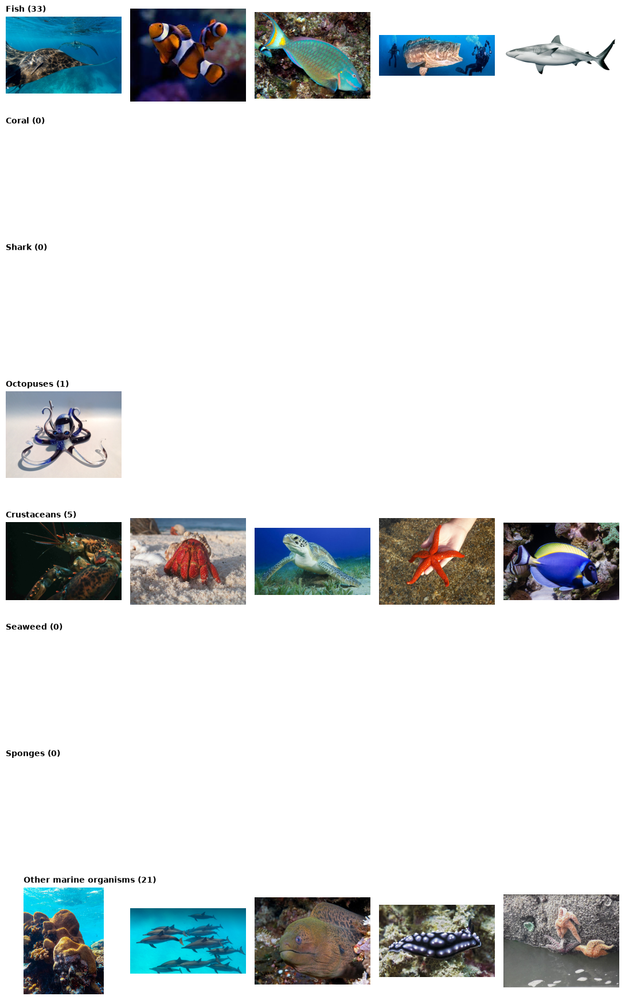


ANALISIS:
Contoh visual tiap kelas menunjukkan variasi sudut pandang, pencahayaan, latar belakang, dan ukuran objek. Kelas dengan bentuk yang mirip berpotensi saling tertukar, sehingga augmentasi data digunakan untuk menambah variasi. Angka dalam kurung menunjukkan jumlah gambar berlabel.

GRAFIK BERHASIL DISIMPAN!
Lokasi: output_oceaniclife\2_class_examples.png


In [14]:

# ==========================================
# (c) CONTOH GAMBAR TIAP KELAS
# ==========================================

import os
import random
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# ==========================================
# 1. KONFIGURASI
# ==========================================

N_EX = 5

SEED = 42

NUM_CLASSES = len(class_names)

os.makedirs(OUT_DIR, exist_ok=True)

# Memastikan analysis tersedia
if "analysis" not in globals():
    analysis = {}

# Memastikan DataFrame tersedia
if "df" not in globals():
    raise ValueError(
        "DataFrame df belum tersedia. Jalankan cell membaca label terlebih dahulu."
    )

# Memastikan kolom tersedia
if "label" not in df.columns or "path" not in df.columns:
    raise ValueError(
        "Kolom label atau path tidak ditemukan. Jalankan ulang cell pemeriksaan label."
    )

# ==========================================
# 2. VISUALISASI CONTOH GAMBAR
# ==========================================

fig, axes = plt.subplots(
    NUM_CLASSES,
    N_EX,
    figsize=(2.2 * N_EX, 2.2 * NUM_CLASSES),
    squeeze=False
)

for r, class_name in enumerate(class_names):

    sub = df[df["label"] == class_name]

    # Memilih maksimal 5 gambar secara acak
    if len(sub) > 0:
        pick = sub.sample(
            n=min(N_EX, len(sub)),
            random_state=SEED
        )["path"].tolist()
    else:
        pick = []

    for k in range(N_EX):

        ax = axes[r, k]
        ax.axis("off")

        if k < len(pick):

            try:
                with Image.open(pick[k]) as img:
                    ax.imshow(img.convert("RGB"))

            except Exception as e:
                ax.text(
                    0.5, 0.5,
                    "Gambar gagal dibuka",
                    ha="center",
                    va="center",
                    fontsize=8
                )

        if k == 0:
            ax.set_title(
                f"{class_name} ({len(sub)})",
                fontsize=10,
                loc="left",
                fontweight="bold"
            )

# ==========================================
# 3. MENYIMPAN HASIL
# ==========================================

plt.tight_layout()

save_path = os.path.join(
    OUT_DIR,
    "2_class_examples.png"
)

plt.savefig(
    save_path,
    dpi=110,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 4. ANALISIS HASIL
# ==========================================

analysis["eda_contoh"] = (
    "Contoh visual tiap kelas menunjukkan variasi sudut pandang, "
    "pencahayaan, latar belakang, dan ukuran objek. "
    "Kelas dengan bentuk yang mirip berpotensi saling tertukar, "
    "sehingga augmentasi data digunakan untuk menambah variasi. "
    "Angka dalam kurung menunjukkan jumlah gambar berlabel."
)

print("\nANALISIS:")
print(analysis["eda_contoh"])

print("\nGRAFIK BERHASIL DISIMPAN!")
print("Lokasi:", save_path)


In [17]:
# ==========================================
# CEK JUMLAH GAMBAR SETIAP KELAS
# ==========================================

print("Jumlah gambar setiap kelas:\n")

jumlah_kelas = (
    df["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print(jumlah_kelas)

print("\nKelas yang memiliki kurang dari 2 gambar:")
print(jumlah_kelas[jumlah_kelas < 2])

Jumlah gambar setiap kelas:

label
Fish                      33
Coral                      0
Shark                      0
Octopuses                  1
Crustaceans                5
Seaweed                    0
Sponges                    0
Other marine organisms    21
Name: count, dtype: int64

Kelas yang memiliki kurang dari 2 gambar:
label
Coral        0
Shark        0
Octopuses    1
Seaweed      0
Sponges      0
Name: count, dtype: int64


In [18]:
# ==========================================
# CEK GAMBAR YANG BELUM DILABELI
# ==========================================

import os
import pandas as pd

label_file = os.path.join(OUT_DIR, "oceaniclife_labels.csv")

df = pd.read_csv(label_file)

# Ambil nama/path gambar yang sudah dilabeli
sudah_dilabeli = set(df["filename"].astype(str))

# Cari gambar yang belum dilabeli
belum_dilabeli = [
    path for path in image_paths
    if os.path.relpath(path, BASE_DIR) not in sudah_dilabeli
]

print("Total gambar       :", len(image_paths))
print("Sudah dilabeli     :", len(df))
print("Belum dilabeli     :", len(belum_dilabeli))


Total gambar       : 7990
Sudah dilabeli     : 60
Belum dilabeli     : 7930


Batch berhasil disimpan!
Total sudah dilabeli: 120
Sisa gambar: 7870


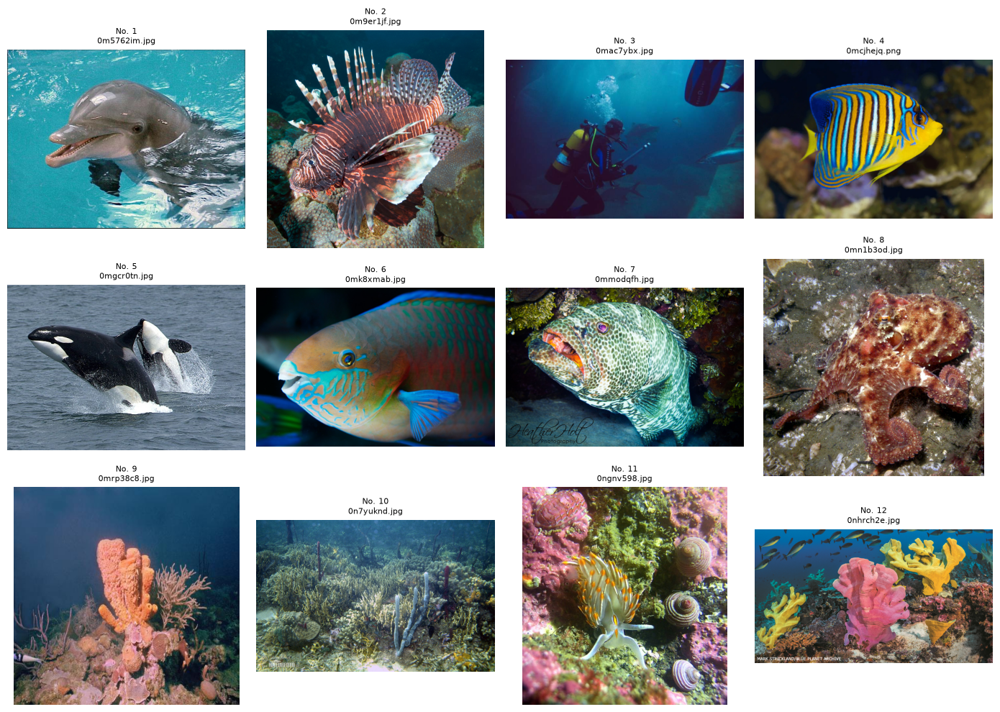


LABEL GAMBAR:
0 = Fish
1 = Coral
2 = Shark
3 = Octopuses
4 = Crustaceans
5 = Seaweed
6 = Sponges
7 = Other marine organisms

Masukkan angka label sesuai urutan gambar.
Contoh: 012345670123
Ketik q untuk berhenti.
Pelabelan dihentikan.

Pelabelan selesai atau dihentikan.
File tersimpan di: output_oceaniclife\oceaniclife_labels.csv


In [19]:
# ==========================================
# MELANJUTKAN PELABELAN GAMBAR
# ==========================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, clear_output

# Pengaturan
BASE_DIR = r"C:\Users\ASUS\OneDrive\Documents\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset"
OUT_DIR = "output_oceaniclife"
LABEL_FILE = os.path.join(OUT_DIR, "oceaniclife_labels.csv")

GRID = 12

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

os.makedirs(OUT_DIR, exist_ok=True)

# ==========================================
# MENGAMBIL SELURUH GAMBAR
# ==========================================

extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

image_paths = []

for root, dirs, files in os.walk(BASE_DIR):
    for file in files:
        if file.lower().endswith(extensions):
            image_paths.append(os.path.join(root, file))

image_paths.sort()

# ==========================================
# MEMBACA LABEL YANG SUDAH ADA
# ==========================================

columns = ["filepath", "filename", "label", "label_id"]

if os.path.exists(LABEL_FILE):
    df = pd.read_csv(LABEL_FILE)
else:
    df = pd.DataFrame(columns=columns)

# Pastikan kolom tersedia
for col in columns:
    if col not in df.columns:
        df[col] = None

# Nama file relatif agar tidak dilabeli ulang
sudah_dilabeli = set(
    df["filename"].dropna().astype(str)
)

belum_dilabeli = [
    path for path in image_paths
    if os.path.relpath(path, BASE_DIR) not in sudah_dilabeli
]

print("Total gambar       :", len(image_paths))
print("Sudah dilabeli     :", len(sudah_dilabeli))
print("Belum dilabeli     :", len(belum_dilabeli))

# ==========================================
# PROSES PELABELAN BATCH
# ==========================================

for start in range(0, len(belum_dilabeli), GRID):

    batch = belum_dilabeli[start:start + GRID]

    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        ax.axis("off")

        if i < len(batch):
            path = batch[i]

            try:
                with Image.open(path) as img:
                    ax.imshow(img.convert("RGB"))

                ax.set_title(
                    f"No. {i+1}\n{os.path.basename(path)[:22]}",
                    fontsize=8
                )

            except Exception:
                ax.set_title(f"No. {i+1}\nGambar error")

    plt.tight_layout()
    plt.show()

    print("\nLABEL GAMBAR:")
    for i, name in enumerate(class_names):
        print(f"{i} = {name}")

    print("\nMasukkan angka label sesuai urutan gambar.")
    print("Contoh: 012345670123")
    print("Ketik q untuk berhenti.")

    while True:
        jawaban = input(
            f"Masukkan {len(batch)} digit label: "
        ).strip()

        if jawaban.lower() == "q":
            print("Pelabelan dihentikan.")
            break

        if (
            len(jawaban) == len(batch)
            and jawaban.isdigit()
            and all(int(x) in range(8) for x in jawaban)
        ):
            break

        print("Input tidak valid. Masukkan angka 0 sampai 7 sesuai jumlah gambar.")

    if jawaban.lower() == "q":
        break

    # Simpan hasil batch
    new_rows = []

    for path, digit in zip(batch, jawaban):
        label_id = int(digit)

        new_rows.append({
            "filepath": path,
            "filename": os.path.relpath(path, BASE_DIR),
            "label": class_names[label_id],
            "label_id": label_id
        })

    df = pd.concat(
        [df, pd.DataFrame(new_rows)],
        ignore_index=True
    )

    df.to_csv(LABEL_FILE, index=False)

    clear_output(wait=True)

    print("Batch berhasil disimpan!")
    print("Total sudah dilabeli:", len(df))
    print("Sisa gambar:", len(image_paths) - len(df))

print("\nPelabelan selesai atau dihentikan.")
print("File tersimpan di:", LABEL_FILE)

In [28]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# =====================================
# 1. PEMBAGIAN DATASET
# =====================================

df_training = df.dropna(subset=["filepath", "label_id"]).copy()
df_training["label_id"] = df_training["label_id"].astype(int)

train_df, temp_df = train_test_split(
    df_training,
    test_size=0.30,
    random_state=SEED,
    shuffle=True
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    shuffle=True
)

# =====================================
# 2. MENGHITUNG CLASS WEIGHT
# =====================================

labels_train = train_df["label_id"].values
kelas_train = np.unique(labels_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=kelas_train,
    y=labels_train
)

class_weight = dict(zip(kelas_train, weights))

# =====================================
# 3. MENAMPILKAN HASIL
# =====================================

print("Data Training   :", len(train_df))
print("Data Validation :", len(val_df))
print("Data Testing    :", len(test_df))

print("\nClass Weight:")
print(class_weight)

print("\nPreprocessing berhasil!")

Data Training   : 84
Data Validation : 18
Data Testing    : 18

Class Weight:
{np.int64(0): np.float64(0.3088235294117647), np.int64(1): np.float64(10.5), np.int64(2): np.float64(5.25), np.int64(3): np.float64(2.625), np.int64(4): np.float64(1.3125), np.int64(5): np.float64(5.25), np.int64(6): np.float64(10.5), np.int64(7): np.float64(0.328125)}

Preprocessing berhasil!


In [30]:
import tensorflow as tf
import numpy as np

AUTOTUNE = tf.data.AUTOTUNE

def load_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.uint8)

    label = tf.one_hot(
        tf.cast(label, tf.int32),
        NUM_CLASSES
    )

    return image, label


def create_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label_id"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Dataset TensorFlow berhasil dibuat!")

Dataset TensorFlow berhasil dibuat!


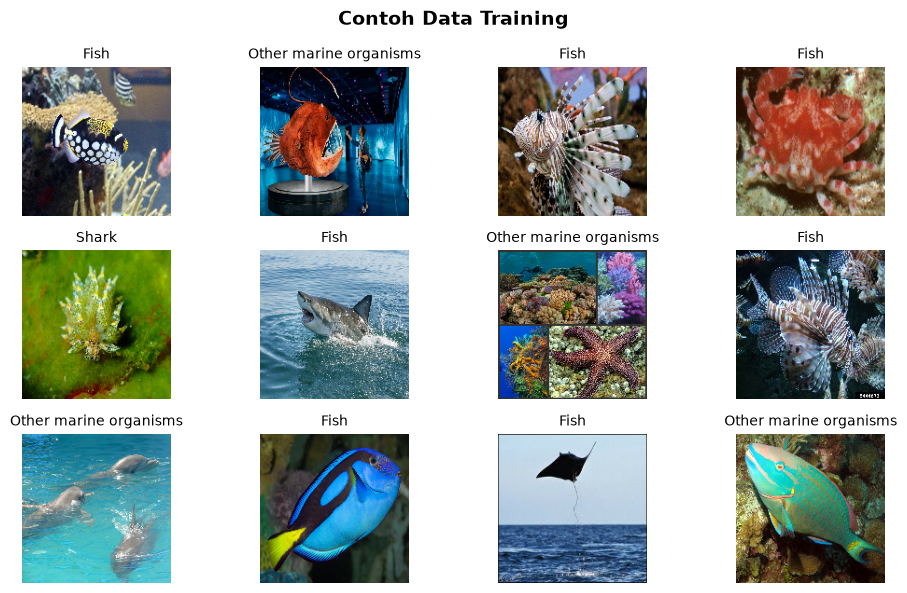

In [31]:
plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(
            class_names[int(np.argmax(labels[i]))],
            fontsize=10
        )
        plt.axis("off")

plt.suptitle("Contoh Data Training", fontsize=14, fontweight="bold")
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "4_sample_data.png"),
    dpi=120
)

plt.show()

In [34]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================

import os
import ssl
import certifi
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# ==========================================
# 2. PENGATURAN MODEL
# ==========================================

IMG_SIZE = (160, 160)
NUM_CLASSES = 8
WEIGHTS = "imagenet"

EPOCHS = 15
FINE_TUNE_EPOCHS = 5

OUT_DIR = "output_oceaniclife"
os.makedirs(OUT_DIR, exist_ok=True)

print("Pengaturan model berhasil!")

# ==========================================
# 3. PENGATURAN SSL
# ==========================================

try:
    os.environ["SSL_CERT_FILE"] = certifi.where()
    os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

    ssl._create_default_https_context = (
        lambda *args, **kwargs:
        ssl.create_default_context(cafile=certifi.where())
    )

except ImportError:
    print("Menggunakan pengaturan SSL default.")

# ==========================================
# 4. DATA AUGMENTATION
# ==========================================

augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

# ==========================================
# 5. BASE MODEL MOBILENETV2
# ==========================================

try:
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights=WEIGHTS
    )

    print("Bobot ImageNet berhasil dimuat!")

except Exception as e:
    print("Gagal memuat ImageNet:", e)
    print("Model akan menggunakan bobot awal.")

    WEIGHTS = None

    base_model = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights=None
    )

base_model.trainable = False

# ==========================================
# 6. MEMBANGUN MODEL CNN
# ==========================================

inputs = layers.Input(shape=IMG_SIZE + (3,))

x = augment(inputs)

x = layers.Rescaling(
    1.0 / 127.5,
    offset=-1
)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(
    inputs,
    outputs,
    name="oceaniclife_mobilenetv2"
)

# ==========================================
# 7. COMPILE MODEL
# ==========================================

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================
# 8. RINGKASAN MODEL
# ==========================================

model.summary()

print("\nModel MobileNetV2 berhasil dibuat!")

Pengaturan model berhasil!
Bobot ImageNet berhasil dimuat!


Model: "oceaniclife_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Model MobileNetV2 berhasil dibuat!


In [35]:
os.makedirs(OUT_DIR, exist_ok=True)

In [37]:
import os
import time

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from tensorflow.keras.optimizers import Adam

ckpt_path = os.path.join(
    OUT_DIR,
    "oceaniclife_cnn_best.keras"
)

def make_callbacks():
    return [
        EarlyStopping(
            monitor="val_accuracy",
            patience=4,
            restore_best_weights=True
        ),

        ModelCheckpoint(
            ckpt_path,
            monitor="val_accuracy",
            save_best_only=True
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=1,
            min_lr=1e-6
        )
    ]

In [38]:
ckpt_path = os.path.join(OUT_DIR, "oceaniclife_cnn_best.keras")


def make_callbacks():
    return [
        EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
        ModelCheckpoint(ckpt_path, monitor="val_accuracy", save_best_only=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6),
    ]


t0 = time.time()

print("\n Fase 1: latih classifier head...")
h1 = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    class_weight=class_weight,
    callbacks=make_callbacks()
)

print("\n Fase 2: fine-tune 30 layer terakhir...")
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

h2 = model.fit(
    train_ds,
    epochs=FINE_TUNE_EPOCHS,
    validation_data=val_ds,
    class_weight=class_weight,
    callbacks=make_callbacks()
)

print(f"\n Total waktu training: {(time.time() - t0) / 60:.1f} menit")

# gabungkan history kedua fase
history = {
    k: [float(v) for v in h1.history[k] + h2.history[k]]
    for k in h1.history
}
split = len(h1.history["accuracy"])


 Fase 1: latih classifier head...
Epoch 1/15


c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.1429 - loss: 3.1146 - val_accuracy: 0.2222 - val_loss: 2.3604 - learning_rate: 0.0010
Epoch 2/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 513ms/step - accuracy: 0.2024 - loss: 2.0591 - val_accuracy: 0.4444 - val_loss: 2.2306 - learning_rate: 0.0010
Epoch 3/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 404ms/step - accuracy: 0.2262 - loss: 2.2501 - val_accuracy: 0.3889 - val_loss: 2.1836 - learning_rate: 0.0010
Epoch 4/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 575ms/step - accuracy: 0.2738 - loss: 1.7972 - val_accuracy: 0.3889 - val_loss: 2.1478 - learning_rate: 0.0010
Epoch 5/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 436ms/step - accuracy: 0.3690 - loss: 1.9891 - val_accuracy: 0.3889 - val_loss: 2.1225 - learning_rate: 0.0010
Epoch 6/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 323ms/step - accuracy: 0.3333 - loss: 1.6681 - val_accuracy: 0.3889 - val_loss: 2.1148 - learning_rate: 0.0010

 Fase 2: fine-tune 30 layer terakhir...
Epoch 1/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.2738 - loss:


Akurasi Testing Akhir: 38.89%
Loss Testing: 1.8215


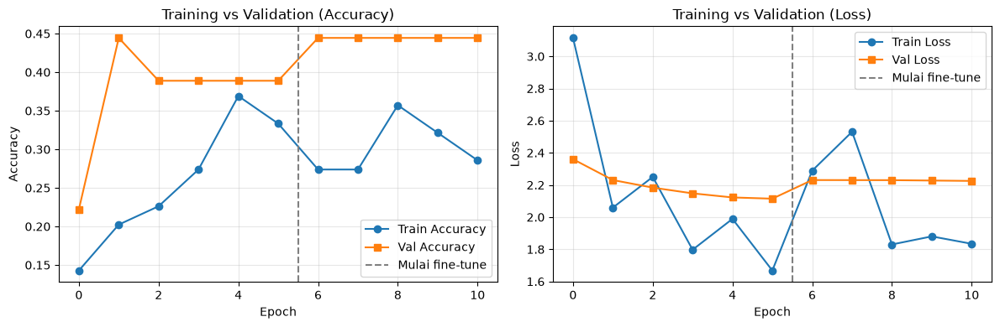


Analisis: Training berjalan 11 epoch (fase 1: 6, fase 2: 5). Akurasi akhir train 28.57% vs validasi 44.44%. Gap train-validasi kecil -> model cukup generalisasi. Loss yang turun lalu mendatar menandakan model sudah konvergen; garis putus-putus menandai awal fine-tuning. Akurasi train bisa tampak lebih rendah dari validasi karena augmentasi & dropout aktif saat training.


In [39]:
# 1. Evaluasi akhir menggunakan data testing
loss, acc = model.evaluate(test_ds, verbose=0)

print(f"\nAkurasi Testing Akhir: {acc * 100:.2f}%")
print(f"Loss Testing: {loss:.4f}")
# 2. Grafik akurasi dan loss
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for a, (metric, title) in zip(ax, [("accuracy", "Accuracy"), ("loss", "Loss")]):
    a.plot(history[metric], "o-", label=f"Train {title}")
    a.plot(history[f"val_{metric}"], "s-", label=f"Val {title}")

    if 0 < split < len(history[metric]):
        a.axvline(split - 0.5, color="gray", linestyle="--", label="Mulai fine-tune")

    a.set_title(f"Training vs Validation ({title})")
    a.set_xlabel("Epoch")
    a.set_ylabel(title)
    a.legend()
    a.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "5_training_curves.png"), dpi=120, bbox_inches="tight")
plt.show()

gap = history["accuracy"][-1] - history["val_accuracy"][-1]
fit_txt = ("Gap train-validasi besar -> indikasi overfitting." if gap > 0.1
           else "Gap train-validasi kecil -> model cukup generalisasi.")
analysis["kurva"] = (
    f"Training berjalan {len(history['loss'])} epoch (fase 1: {split}, fase 2: {len(history['loss']) - split}). "
    f"Akurasi akhir train {history['accuracy'][-1]:.2%} vs validasi {history['val_accuracy'][-1]:.2%}. {fit_txt} "
    "Loss yang turun lalu mendatar menandakan model sudah konvergen; garis putus-putus menandai awal fine-tuning. "
    "Akurasi train bisa tampak lebih rendah dari validasi karena augmentasi & dropout aktif saat training."
)
print("\nAnalisis:", analysis["kurva"])

In [41]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_recall_fscore_support
)

# ==========================================
# 2. EVALUASI DATA TESTING
# ==========================================

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

# ==========================================
# 3. MENGHASILKAN LABEL PREDIKSI
# ==========================================

y_true, y_pred = [], []
imgs_keep, probs_keep = [], []

for xb, yb in test_ds:
    p = model.predict(xb, verbose=0)

    y_true.extend(np.argmax(yb.numpy(), axis=1))
    y_pred.extend(np.argmax(p, axis=1))

    n_keep = min(16 - len(imgs_keep), len(xb))

    if n_keep > 0:
        imgs_keep.extend(xb[:n_keep].numpy())
        probs_keep.extend(p[:n_keep])

y_true = np.asarray(y_true, dtype=int)
y_pred = np.asarray(y_pred, dtype=int)
probs_keep = np.asarray(probs_keep)

present = sorted(np.unique(y_true).tolist())
present_names = [class_names[i] for i in present]

print("\nJumlah data uji:", len(y_true))

# ==========================================
# 4. CLASSIFICATION REPORT
# ==========================================

print("\nCLASSIFICATION REPORT\n")

print(classification_report(
    y_true,
    y_pred,
    labels=present,
    target_names=present_names,
    digits=3,
    zero_division=0
))

rep = classification_report(
    y_true,
    y_pred,
    labels=present,
    target_names=present_names,
    output_dict=True,
    zero_division=0
)

per_class = pd.DataFrame(rep).T

per_class = per_class.reindex(present_names)[
    ["precision", "recall", "f1-score", "support"]
].fillna(0)

per_class.to_csv(
    os.path.join(OUT_DIR, "per_class.csv")
)

# ==========================================
# 5. RINGKASAN METRIK
# ==========================================

acc_final = float(accuracy_score(y_true, y_pred))

p_m, r_m, f_m, _ = precision_recall_fscore_support(
    y_true, y_pred,
    labels=present,
    average="macro",
    zero_division=0
)

p_w, r_w, f_w, _ = precision_recall_fscore_support(
    y_true, y_pred,
    labels=present,
    average="weighted",
    zero_division=0
)

summary = pd.DataFrame({
    "Accuracy": [acc_final, acc_final],
    "Precision": [p_m, p_w],
    "Recall": [r_m, r_w],
    "F1-score": [f_m, f_w]
}, index=["Macro avg", "Weighted avg"])

print("\nRINGKASAN METRIK\n")
print(summary.round(4).to_string())

# ==========================================
# 6. MENYIMPAN METRIK
# ==========================================

metrics = {
    "accuracy": acc_final,
    "loss": float(test_loss),

    "macro": {
        "precision": float(p_m),
        "recall": float(r_m),
        "f1": float(f_m)
    },

    "weighted": {
        "precision": float(p_w),
        "recall": float(r_w),
        "f1": float(f_w)
    },

    "n_train": int(len(train_df)),
    "n_val": int(len(val_df)),
    "n_test": int(len(y_true)),

    "img_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,

    "epochs_fase1": int(split),
    "epochs_fase2": int(len(history["loss"]) - split),

    "class_names": class_names
}

with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=4)

with open(os.path.join(OUT_DIR, "history.json"), "w") as f:
    json.dump(history, f, indent=4)

# ==========================================
# 7. ANALISIS HASIL
# ==========================================

f1_present = per_class["f1-score"]

best_c = f1_present.idxmax()
worst_c = f1_present.idxmin()

level = (
    "sangat baik" if acc_final >= 0.9
    else "baik" if acc_final >= 0.8
    else "cukup" if acc_final >= 0.6
    else "masih rendah"
)

analysis = {}

analysis["metrik"] = (
    f"Akurasi {acc_final:.2%} ({level}). "
    f"Macro F1 {f_m:.2%}, Precision {p_m:.2%}, "
    f"dan Recall {r_m:.2%}. "
    f"Kelas paling mudah dikenali: {best_c} "
    f"(F1 {f1_present[best_c]:.2f}); "
    f"kelas paling sulit: {worst_c} "
    f"(F1 {f1_present[worst_c]:.2f})."
)

print("\nANALISIS:", analysis["metrik"])

print("\nSemua hasil evaluasi berhasil disimpan!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.3889 - loss: 1.8215

Jumlah data uji: 18

CLASSIFICATION REPORT

                        precision    recall  f1-score   support

                  Fish      0.714     0.385     0.500        13
           Crustaceans      0.000     0.000     0.000         2
Other marine organisms      0.333     0.667     0.444         3

             micro avg      0.438     0.389     0.412        18
             macro avg      0.349     0.350     0.315        18
          weighted avg      0.571     0.389     0.435        18


RINGKASAN METRIK

              Accuracy  Precision  Recall  F1-score
Macro avg       0.3889     0.3492  0.3504    0.3148
Weighted avg    0.3889     0.5714  0.3889    0.4352

ANALISIS: Akurasi 38.89% (masih rendah). Macro F1 31.48%, Precision 34.92%, dan Recall 35.04%. Kelas paling mudah dikenali: Fish (F1 0.50); kelas paling sulit: Crustaceans (F1 0.00).

Semua hasil evaluasi berhasil disimpan!


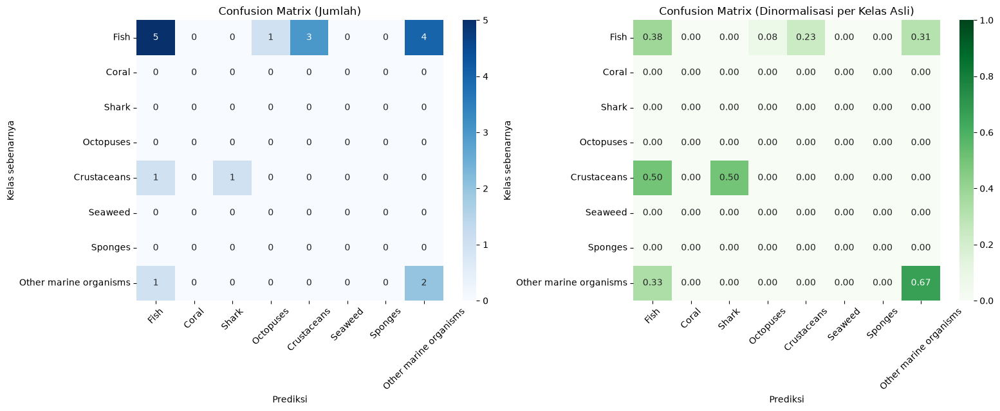


Analisis Confusion Matrix:
Diagonal utama menunjukkan prediksi benar. Kesalahan terbanyak: 'Fish' diprediksi sebagai 'Other marine organisms' (4 gambar), kemungkinan karena kemiripan visual. Kelas dengan recall terendah adalah 'Crustaceans' (0.00).

Confusion Matrix berhasil dibuat!


In [43]:
# ==========================================
# 5. CONFUSION MATRIX
# ==========================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Membuat confusion matrix
labels_all = list(range(NUM_CLASSES))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels_all
)

# Simpan confusion matrix
np.save(
    os.path.join(OUT_DIR, "confusion_matrix.npy"),
    cm
)

# Normalisasi per kelas sebenarnya
row_sum = cm.sum(axis=1, keepdims=True)

cm_pct = np.divide(
    cm,
    row_sum,
    out=np.zeros_like(cm, dtype=float),
    where=row_sum != 0
)

# ==========================================
# VISUALISASI CONFUSION MATRIX
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)

axes[0].set_title("Confusion Matrix (Jumlah)")

sns.heatmap(
    cm_pct,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    vmin=0,
    vmax=1,
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)

axes[1].set_title(
    "Confusion Matrix (Dinormalisasi per Kelas Asli)"
)

for a in axes:
    a.set_xlabel("Prediksi")
    a.set_ylabel("Kelas sebenarnya")
    a.tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "6_confusion_matrix.png"),
    dpi=120,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# ANALISIS CONFUSION MATRIX
# ==========================================

off = cm.copy()
np.fill_diagonal(off, 0)

if off.max() > 0:
    a_, b_ = np.unravel_index(
        off.argmax(),
        off.shape
    )

    conf_txt = (
        f"Kesalahan terbanyak: '{class_names[a_]}' "
        f"diprediksi sebagai '{class_names[b_]}' "
        f"({off[a_, b_]} gambar), kemungkinan karena kemiripan visual."
    )
else:
    conf_txt = "Tidak ada kesalahan klasifikasi pada data uji."

diag = np.diag(cm_pct)[present]

analysis["confusion_matrix"] = (
    f"Diagonal utama menunjukkan prediksi benar. "
    f"{conf_txt} Kelas dengan recall terendah adalah "
    f"'{class_names[present[int(diag.argmin())]]}' "
    f"({diag.min():.2f})."
)

print("\nAnalisis Confusion Matrix:")
print(analysis["confusion_matrix"])

print("\nConfusion Matrix berhasil dibuat!")

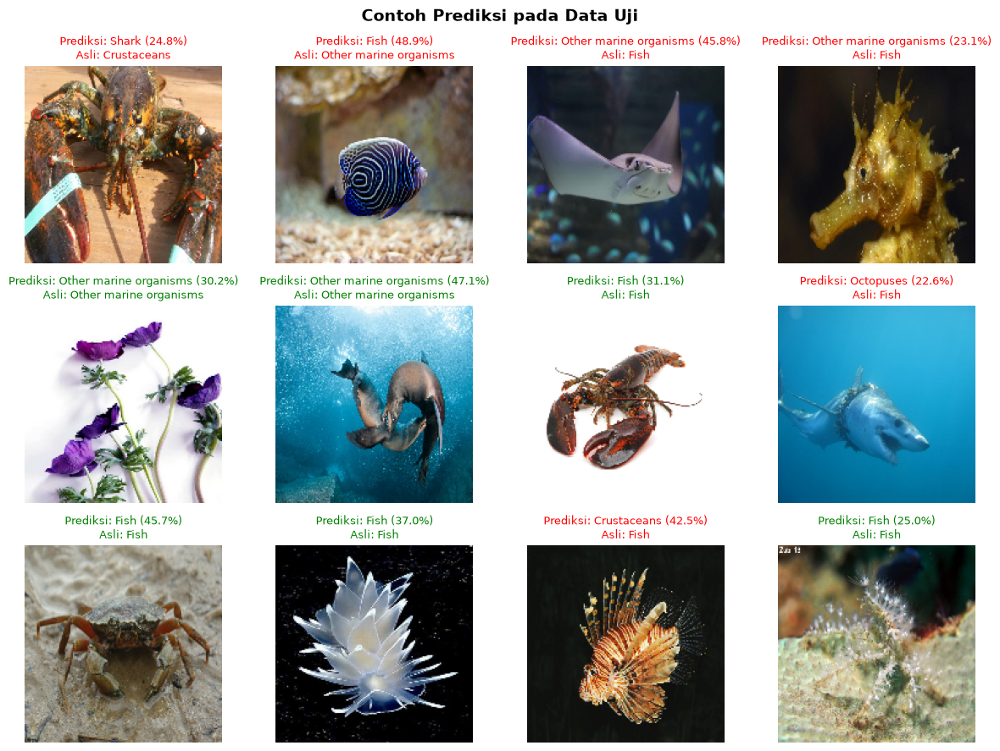

Analisis: Dari 12 gambar uji, 6 diprediksi benar (judul hijau) dan 6 salah (merah). Persentase di judul adalah confidence model; prediksi salah dengan confidence tinggi menandakan kelas yang sangat mirip secara visual.


In [44]:
# 6. Contoh prediksi gambar
n_show = min(12, len(imgs_keep))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for i, a in enumerate(axes):
    if i >= n_show:
        a.axis("off")
        continue

    img = np.clip(imgs_keep[i] / 255.0, 0, 1)
    pred = int(np.argmax(probs_keep[i]))
    true = int(y_true[i])
    conf = probs_keep[i][pred] * 100

    a.imshow(img)
    a.set_title(
        f"Prediksi: {class_names[pred]} ({conf:.1f}%)\nAsli: {class_names[true]}",
        color="green" if pred == true else "red",
        fontsize=9,
    )
    a.axis("off")

plt.suptitle("Contoh Prediksi pada Data Uji", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "7_sample_predictions.png"), dpi=120, bbox_inches="tight")
plt.show()

n_ok = int(sum(int(np.argmax(probs_keep[i])) == int(y_true[i]) for i in range(n_show)))
analysis["prediksi"] = (
    f"Dari {n_show} gambar uji, {n_ok} diprediksi benar (judul hijau) dan {n_show - n_ok} salah (merah). "
    "Persentase di judul adalah confidence model; prediksi salah dengan confidence tinggi menandakan kelas yang "
    "sangat mirip secara visual."
)
print("Analisis:", analysis["prediksi"])

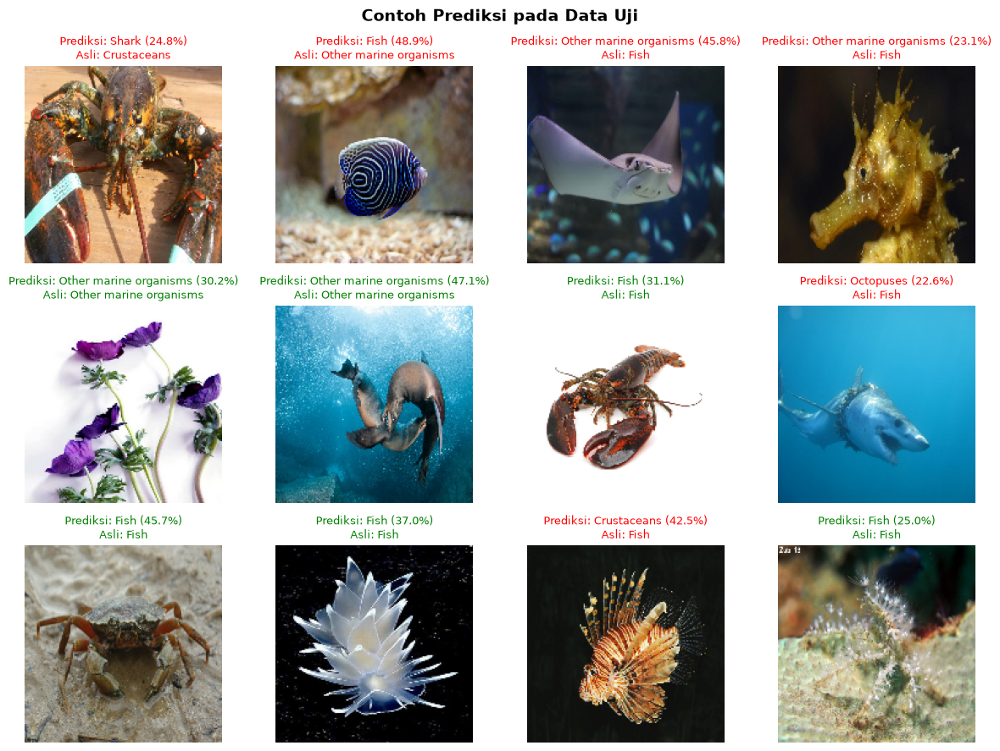

Analisis: Dari 12 gambar uji, 6 diprediksi benar (judul hijau) dan 6 salah (merah). Persentase di judul adalah confidence model; prediksi salah dengan confidence tinggi menandakan kelas yang sangat mirip secara visual.


In [45]:
# 6. Contoh prediksi gambar
n_show = min(12, len(imgs_keep))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for i, a in enumerate(axes):
    if i >= n_show:
        a.axis("off")
        continue

    img = np.clip(imgs_keep[i] / 255.0, 0, 1)
    pred = int(np.argmax(probs_keep[i]))
    true = int(y_true[i])
    conf = probs_keep[i][pred] * 100

    a.imshow(img)
    a.set_title(
        f"Prediksi: {class_names[pred]} ({conf:.1f}%)\nAsli: {class_names[true]}",
        color="green" if pred == true else "red",
        fontsize=9,
    )
    a.axis("off")

plt.suptitle("Contoh Prediksi pada Data Uji", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "7_sample_predictions.png"), dpi=120, bbox_inches="tight")
plt.show()

n_ok = int(sum(int(np.argmax(probs_keep[i])) == int(y_true[i]) for i in range(n_show)))
analysis["prediksi"] = (
    f"Dari {n_show} gambar uji, {n_ok} diprediksi benar (judul hijau) dan {n_show - n_ok} salah (merah). "
    "Persentase di judul adalah confidence model; prediksi salah dengan confidence tinggi menandakan kelas yang "
    "sangat mirip secara visual."
)
print("Analisis:", analysis["prediksi"])

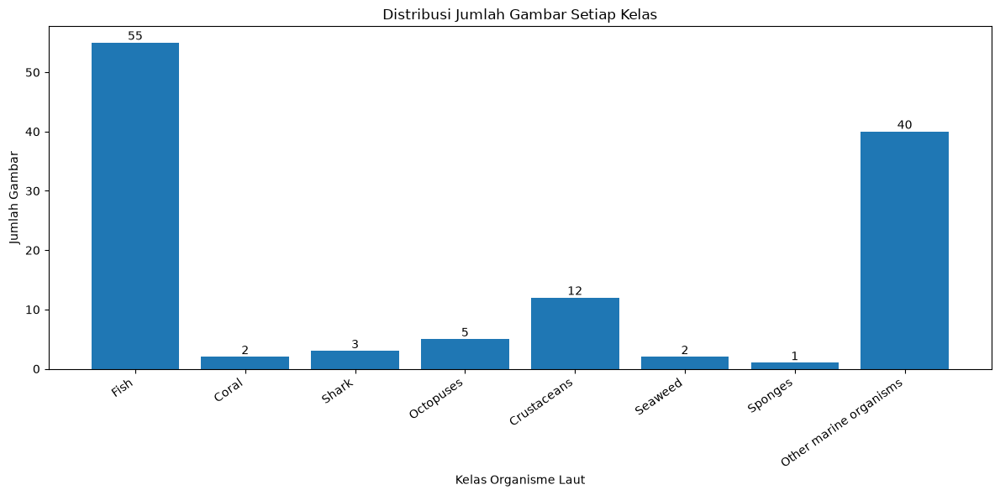

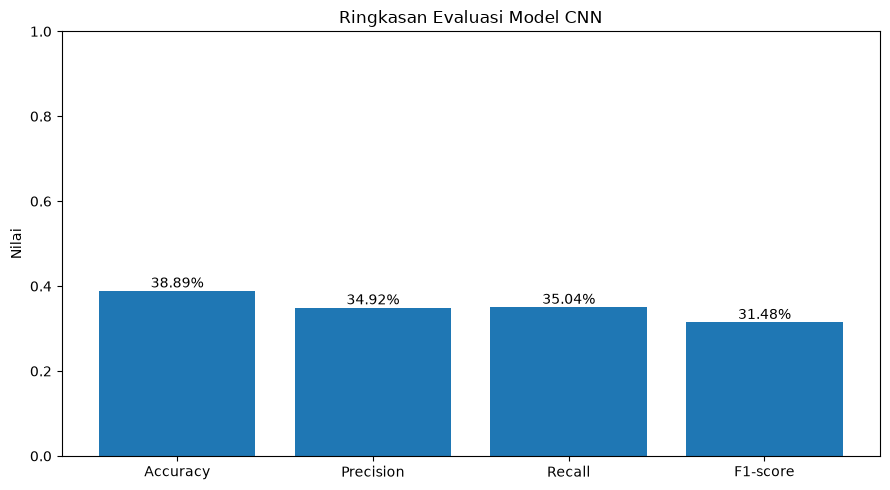


FILE OUTPUT BERHASIL DILENGKAPI!
1_class_distribution.png
2_class_examples.png
3_image_properties.png
4_sample_data.png
5_training_curves.png
6_confusion_matrix.png
7_sample_predictions.png
8_final_metrics.png
analysis.json
class_names.json
confusion_matrix.npy
eda.json
final_marine_cnn_model.keras
history.json
metrics.json
oceaniclife_cnn_best.keras
oceaniclife_labels.csv
per_class.csv


In [48]:

# ==========================================
# MELENGKAPI FILE OUTPUT 1, 8, DAN EDA.JSON
# ==========================================

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs(OUT_DIR, exist_ok=True)

# ==========================================
# 1. MEMBACA DATA LABEL
# ==========================================

df_eda = pd.read_csv(
    os.path.join(OUT_DIR, "oceaniclife_labels.csv")
)

counts = (
    df_eda["label"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

# ==========================================
# 2. GRAFIK DISTRIBUSI KELAS
# ==========================================

plt.figure(figsize=(12, 6))

bars = plt.bar(
    class_names,
    counts.values
)

plt.bar_label(bars)
plt.title("Distribusi Jumlah Gambar Setiap Kelas")
plt.xlabel("Kelas Organisme Laut")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "1_class_distribution.png"),
    dpi=120,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 3. MENYIMPAN EDA.JSON
# ==========================================

eda = {
    "total_gambar_berlabel": int(len(df_eda)),
    "jumlah_kelas": len(class_names),
    "distribusi_kelas": {
        str(k): int(v) for k, v in counts.items()
    },
    "ukuran_input": list(IMG_SIZE),
    "kelas": class_names
}

with open(
    os.path.join(OUT_DIR, "eda.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(eda, f, indent=4, ensure_ascii=False)

# ==========================================
# 4. GRAFIK RINGKASAN HASIL MODEL
# ==========================================

if os.path.exists(os.path.join(OUT_DIR, "metrics.json")):

    with open(
        os.path.join(OUT_DIR, "metrics.json"),
        "r",
        encoding="utf-8"
    ) as f:
        metrics = json.load(f)

    metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]

    values = [
        metrics["accuracy"],
        metrics["macro"]["precision"],
        metrics["macro"]["recall"],
        metrics["macro"]["f1"]
    ]

    plt.figure(figsize=(9, 5))

    bars = plt.bar(metric_names, values)
    plt.bar_label(
        bars,
        labels=[f"{v:.2%}" for v in values]
    )

    plt.ylim(0, 1)
    plt.title("Ringkasan Evaluasi Model CNN")
    plt.ylabel("Nilai")
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUT_DIR, "8_final_metrics.png"),
        dpi=120,
        bbox_inches="tight"
    )

    plt.show()

# ==========================================
# 5. MENAMPILKAN FILE
# ==========================================

print("\nFILE OUTPUT BERHASIL DILENGKAPI!")

for file in sorted(os.listdir(OUT_DIR)):
    print(file)


In [47]:
with open(os.path.join(OUT_DIR, "analysis.json"), "w", encoding="utf-8") as f:
    json.dump(analysis, f, indent=2, ensure_ascii=False)

model.save(os.path.join(OUT_DIR, "final_marine_cnn_model.keras"))

loaded = tf.keras.models.load_model(
    os.path.join(OUT_DIR, "final_marine_cnn_model.keras")
)

print(f'\n Model & semua hasil tersimpan di folder "{OUT_DIR}" dan model berhasil di-load ulang.')

# Jalankan dashboard (dari folder yang berisi app.py dan folder output_oceaniclife):
#   streamlit run app.py


 Model & semua hasil tersimpan di folder "output_oceaniclife" dan model berhasil di-load ulang.
